In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('CEP_2_Datasets/loan_data.csv')
data.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [3]:
print(type(data))
print(data.shape)
print(data.dtypes)
print(data.head())

<class 'pandas.DataFrame'>
(9578, 14)
credit.policy          int64
purpose                  str
int.rate             float64
installment          float64
log.annual.inc       float64
dti                  float64
fico                   int64
days.with.cr.line    float64
revol.bal              int64
revol.util           float64
inq.last.6mths         int64
delinq.2yrs            int64
pub.rec                int64
not.fully.paid         int64
dtype: object
   credit.policy             purpose  int.rate  installment  log.annual.inc  \
0              1  debt_consolidation    0.1189       829.10       11.350407   
1              1         credit_card    0.1071       228.22       11.082143   
2              1  debt_consolidation    0.1357       366.86       10.373491   
3              1  debt_consolidation    0.1008       162.34       11.350407   
4              1         credit_card    0.1426       102.92       11.299732   

     dti  fico  days.with.cr.line  revol.bal  revol.util  inq.last.

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), str(1)
memory usage: 1.0 MB


In [5]:
data.isnull().sum()

credit.policy        0
purpose              0
int.rate             0
installment          0
log.annual.inc       0
dti                  0
fico                 0
days.with.cr.line    0
revol.bal            0
revol.util           0
inq.last.6mths       0
delinq.2yrs          0
pub.rec              0
not.fully.paid       0
dtype: int64

In [6]:
data.describe()



,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


In [7]:
# Identify categorical columns

categorical_cols = data.select_dtypes(
    include=["object", "category", "bool", "str"]
).columns.tolist()

print("Categorical columns:", categorical_cols)

Categorical columns: ['purpose']


In [8]:
# inspect the number of unique values in each categorical column:

for col in categorical_cols:
    print(f"\nColumn: {col}")
    print("Unique categories:", data[col].nunique())
    print(data[col].value_counts(dropna=False))


Column: purpose
Unique categories: 7
purpose
debt_consolidation    3957
all_other             2331
credit_card           1262
home_improvement       629
small_business         619
major_purchase         437
educational            343
Name: count, dtype: int64


In [9]:
# Transform categorical values

# Create a copy so the original dataset remains unchanged
data_transformed = data.copy()

# Transform categorical features using One-Hot Encoding
data_transformed = pd.get_dummies(
    data_transformed,
    columns=categorical_cols,
    dtype=int
)

print("Original shape:", data.shape)
print("Transformed shape:", data_transformed.shape)

display(data_transformed.head())

Original shape: (9578, 14)
Transformed shape: (9578, 20)


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_all_other,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,1,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,0,0,1,0,0,0,0
1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0,0,1,0,0,0,0,0
2,1,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,0,0,1,0,0,0,0
3,1,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,0,0,1,0,0,0,0
4,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0,0,1,0,0,0,0,0


In [10]:
# Validate the transformed dataset

# Check transformed columns
print("Transformed columns:")
print(data_transformed.columns.tolist())

# Check whether any categorical columns remain
remaining_categorical = data_transformed.select_dtypes(
    include=["object", "category", "bool", "str"]
).columns.tolist()

print("\nRemaining categorical columns:", remaining_categorical)

# Check missing values
print("\nMissing values after transformation:")
print(data_transformed.isnull().sum().sum())

# Verify that all columns are numerical
print("\nData types after transformation:")
print(data_transformed.dtypes)


Transformed columns:
['credit.policy', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid', 'purpose_all_other', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_major_purchase', 'purpose_small_business']

Remaining categorical columns: []

Missing values after transformation:
0

Data types after transformation:
credit.policy                   int64
int.rate                      float64
installment                   float64
log.annual.inc                float64
dti                           float64
fico                            int64
days.with.cr.line             float64
revol.bal                       int64
revol.util                    float64
inq.last.6mths                  int64
delinq.2yrs                     int64
pub.rec                         int64
not.fully.paid                  int64
purpose_all

In [11]:

# Step 1: Dataset overview

# Check the number of rows and columns
print("Dataset shape:", data_transformed.shape)

# Display the first five rows
display(data_transformed.head())

# Check data types and non-null values
data_transformed.info()

# Generate descriptive statistics
display(data_transformed.describe())



Dataset shape: (9578, 20)


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_all_other,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,1,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,0,0,1,0,0,0,0
1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0,0,1,0,0,0,0,0
2,1,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,0,0,1,0,0,0,0
3,1,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,0,0,1,0,0,0,0
4,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0,0,1,0,0,0,0,0


<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   credit.policy               9578 non-null   int64  
 1   int.rate                    9578 non-null   float64
 2   installment                 9578 non-null   float64
 3   log.annual.inc              9578 non-null   float64
 4   dti                         9578 non-null   float64
 5   fico                        9578 non-null   int64  
 6   days.with.cr.line           9578 non-null   float64
 7   revol.bal                   9578 non-null   int64  
 8   revol.util                  9578 non-null   float64
 9   inq.last.6mths              9578 non-null   int64  
 10  delinq.2yrs                 9578 non-null   int64  
 11  pub.rec                     9578 non-null   int64  
 12  not.fully.paid              9578 non-null   int64  
 13  purpose_all_other           9578 non-null   

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_all_other,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054,0.243370,0.131760,0.413134,0.035811,0.065671,0.045625,0.064627
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676,0.429139,0.338248,0.492422,0.185829,0.247720,0.208682,0.245880
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [12]:

# Count the target classes
target = "not.fully.paid"

print("Target class counts:")
print(data_transformed[target].value_counts().sort_index())

# Calculate percentages
print("\nTarget class percentages:")
print(
    (data_transformed[target].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)


Target class counts:
not.fully.paid
0    8045
1    1533
Name: count, dtype: int64

Target class percentages:
not.fully.paid
0    83.99
1    16.01
Name: proportion, dtype: float64


Target class counts:
not.fully.paid
0    8045
1    1533
Name: count, dtype: int64

Target class percentages:
not.fully.paid
0    83.99
1    16.01
Name: proportion, dtype: float64


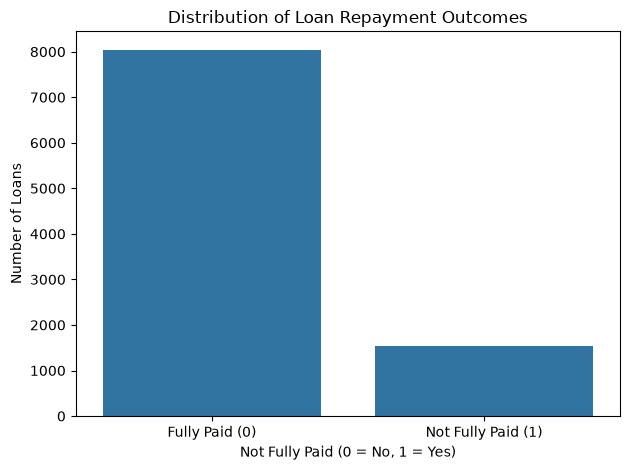

In [13]:

# Count each target class
target = "not.fully.paid"

target_counts = data_transformed[target].value_counts().sort_index()

print("Target class counts:")
print(target_counts)

# Calculate class percentages
target_percentages = (
    data_transformed[target]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nTarget class percentages:")
print(target_percentages.round(2))

# Visualize the class distribution
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=data_transformed, x=target)

plt.title("Distribution of Loan Repayment Outcomes")
plt.xlabel("Not Fully Paid (0 = No, 1 = Yes)")
plt.ylabel("Number of Loans")
plt.xticks([0, 1], ["Fully Paid (0)", "Not Fully Paid (1)"])
plt.tight_layout()
plt.show()


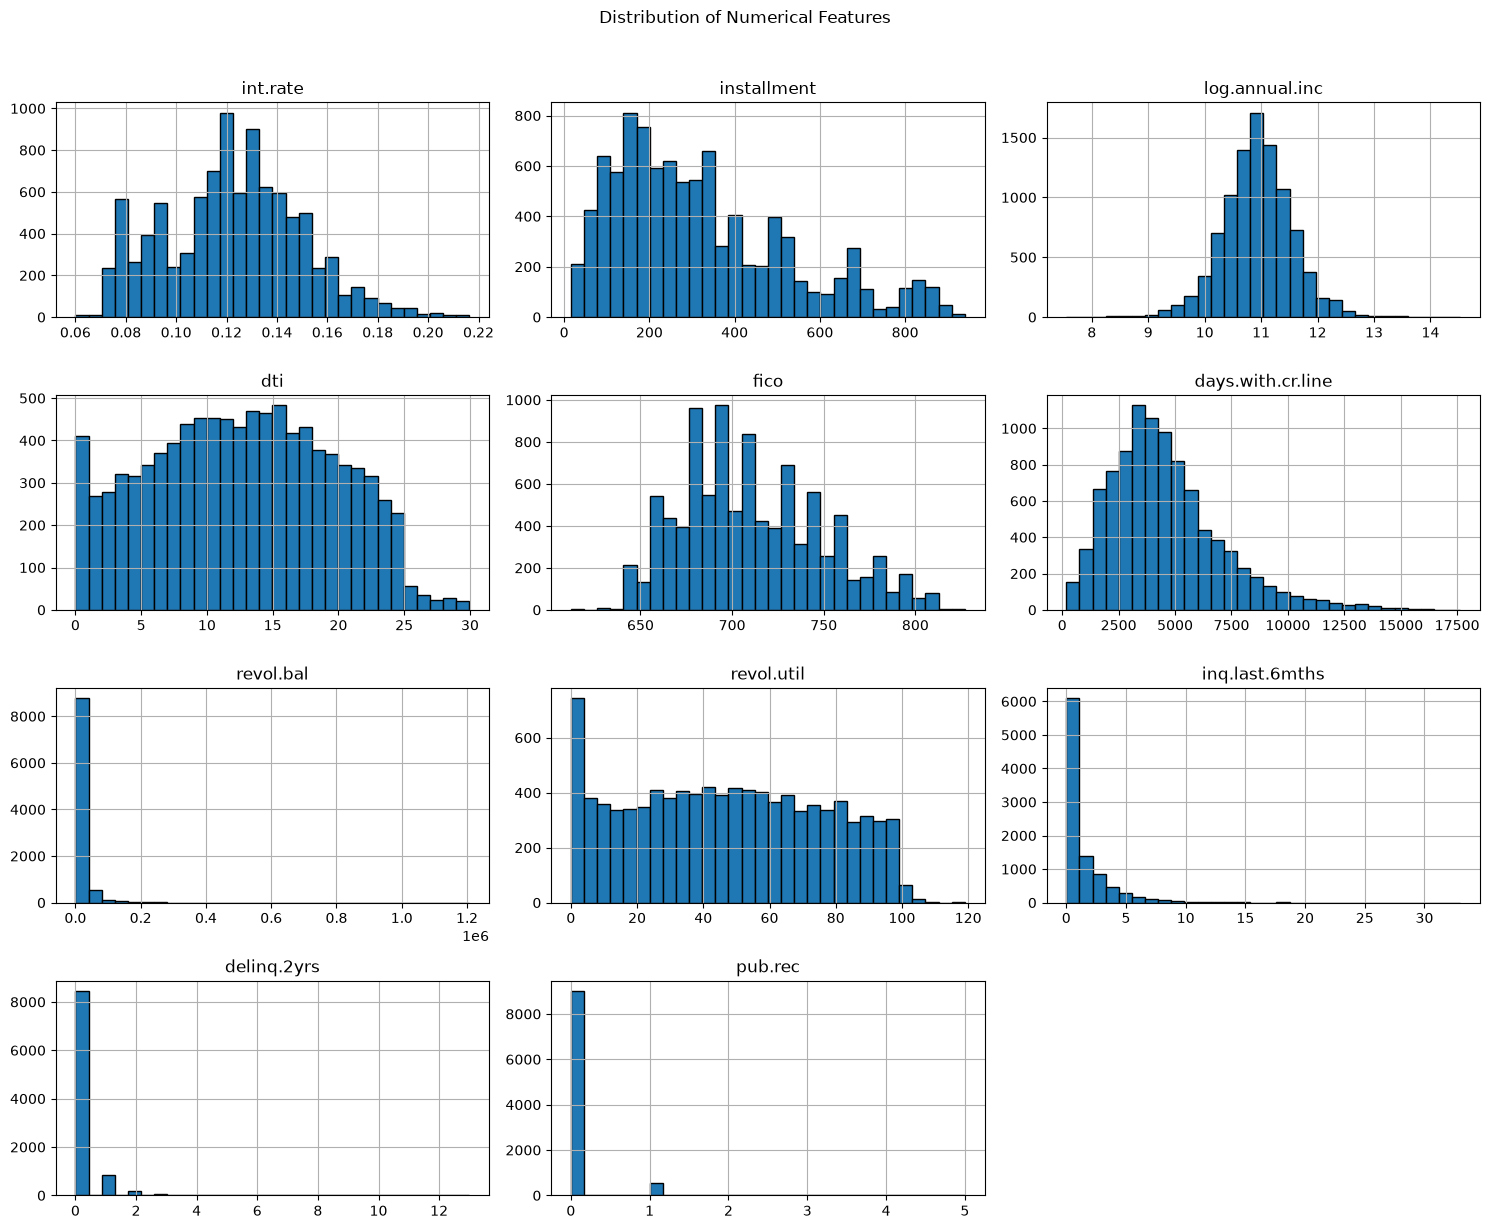

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select important numerical features
numerical_features = [
    "int.rate",
    "installment",
    "log.annual.inc",
    "dti",
    "fico",
    "days.with.cr.line",
    "revol.bal",
    "revol.util",
    "inq.last.6mths",
    "delinq.2yrs",
    "pub.rec"
]

# Plot feature distributions
data_transformed[numerical_features].hist(
    bins=30,
    figsize=(15, 12),
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()


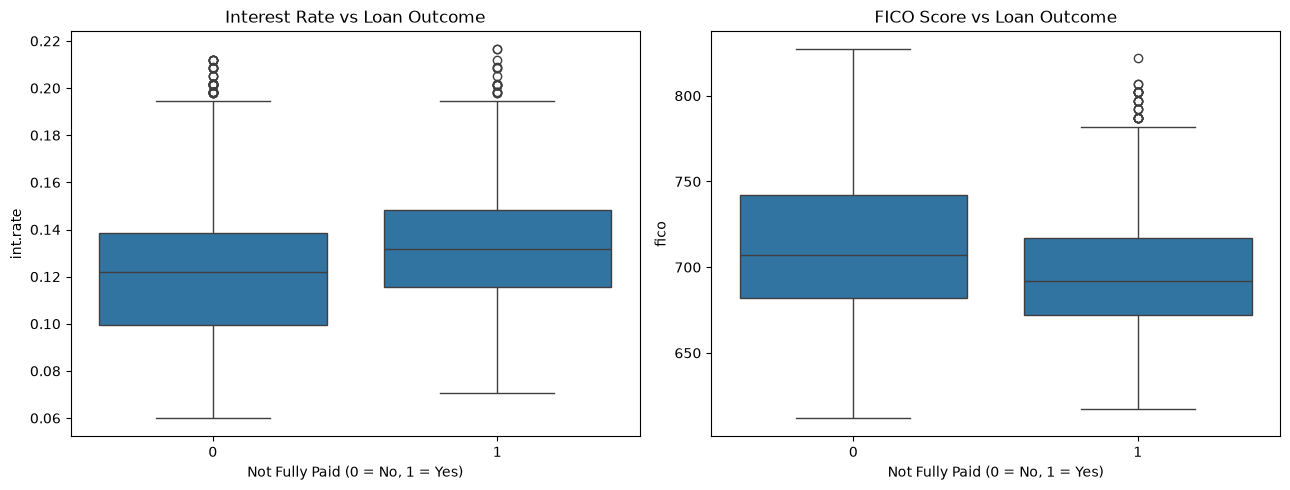

In [15]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=data_transformed,
    x="not.fully.paid",
    y="int.rate",
    ax=axes[0]
)
axes[0].set_title("Interest Rate vs Loan Outcome")
axes[0].set_xlabel("Not Fully Paid (0 = No, 1 = Yes)")

sns.boxplot(
    data=data_transformed,
    x="not.fully.paid",
    y="fico",
    ax=axes[1]
)
axes[1].set_title("FICO Score vs Loan Outcome")
axes[1].set_xlabel("Not Fully Paid (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()


In [16]:

features = [
    "int.rate",
    "fico",
    "dti",
    "installment",
    "revol.util",
    "inq.last.6mths"
]

summary = data_transformed.groupby("not.fully.paid")[features].mean().T

summary.columns = ["Fully Paid (0)", "Not Fully Paid (1)"]

summary["Difference"] = (
    summary["Not Fully Paid (1)"]
    - summary["Fully Paid (0)"]
)

display(summary.round(3))


,Fully Paid (0),Not Fully Paid (1),Difference
int.rate,0.121,0.132,0.012
fico,713.327,697.828,-15.498
dti,12.494,13.196,0.701
installment,314.574,342.785,28.211
revol.util,45.760,52.255,6.495
inq.last.6mths,1.434,2.331,0.897


In [17]:

# Calculate the number of loans and proportion not fully paid by purpose

purpose_analysis = (
    data.groupby("purpose")["not.fully.paid"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Total Loans",
        "sum": "Not Fully Paid Loans",
        "mean": "Not Fully Paid Rate"
    })
)

purpose_analysis["Not Fully Paid Rate"] *= 100

display(purpose_analysis.sort_values(
    "Not Fully Paid Rate",
    ascending=False
).round(2))


,Total Loans,Not Fully Paid Loans,Not Fully Paid Rate
purpose,,,
small_business,619,172,27.79
educational,343,69,20.12
home_improvement,629,107,17.01
all_other,2331,387,16.60
debt_consolidation,3957,603,15.24
credit_card,1262,146,11.57
major_purchase,437,49,11.21


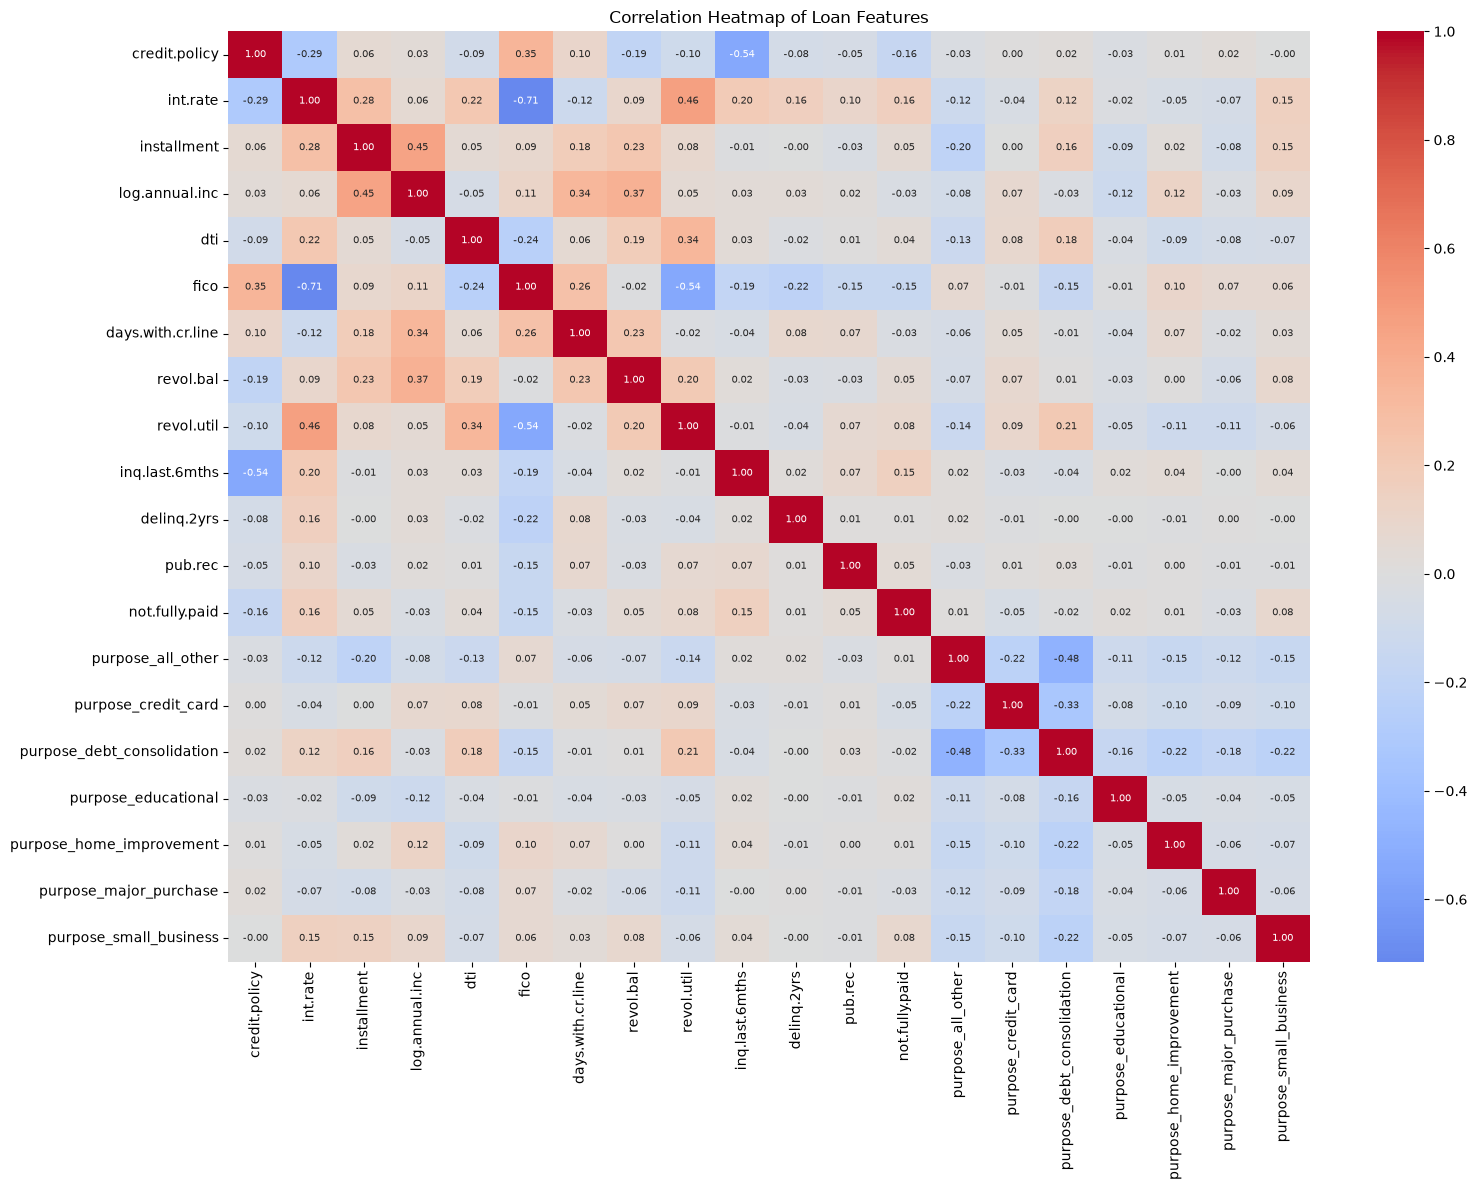

In [18]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlations between numerical columns
correlation = data_transformed.corr(numeric_only=True)

# Visualize the correlation matrix
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    annot=True,
    annot_kws={"size": 7}
)

plt.title("Correlation Heatmap of Loan Features")
plt.tight_layout()
plt.show()


## Exploratory Data Analysis — Conclusion

The LendingClub dataset contains 9,578 loan records and 20 columns after one-hot encoding. The target variable, `not.fully.paid`, is imbalanced: 83.99% of loans belong to Class 0 (fully paid), while 16.01% belong to Class 1 (not fully paid).

The numerical feature distributions show that `revol.bal`, `inq.last.6mths`, `delinq.2yrs`, and `pub.rec` are right-skewed or concentrated around zero. The revolving balance also contains extreme values that should be investigated before selecting a preprocessing strategy.

Comparisons between target groups show that loans that were not fully paid have higher average interest rates, debt-to-income ratios, installments, revolving utilization, and recent credit inquiries. They also have lower average FICO scores.

Loan-purpose analysis shows the highest not-fully-paid rate for small business loans (27.79%) and the lowest for major purchase loans (11.21%). The correlation heatmap shows a negative correlation between FICO score and interest rate (-0.71), while correlations between individual input features and the target are generally weak.

These findings suggest that class imbalance, feature scaling, and evaluation metrics beyond accuracy should be considered when developing the deep learning model. The observed associations are exploratory and do not establish causation or guarantee predictive importance.


In [19]:

# Separate the target from input features
target = "not.fully.paid"

X = data_transformed.drop(columns=[target])

# Calculate correlations between input features only
correlation_matrix = X.corr(numeric_only=True)

display(correlation_matrix.round(2))


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,purpose_all_other,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
credit.policy,1.00,-0.29,0.06,0.03,-0.09,0.35,0.10,-0.19,-0.10,-0.54,-0.08,-0.05,-0.03,0.00,0.02,-0.03,0.01,0.02,-0.00
int.rate,-0.29,1.00,0.28,0.06,0.22,-0.71,-0.12,0.09,0.46,0.20,0.16,0.10,-0.12,-0.04,0.12,-0.02,-0.05,-0.07,0.15
installment,0.06,0.28,1.00,0.45,0.05,0.09,0.18,0.23,0.08,-0.01,-0.00,-0.03,-0.20,0.00,0.16,-0.09,0.02,-0.08,0.15
log.annual.inc,0.03,0.06,0.45,1.00,-0.05,0.11,0.34,0.37,0.05,0.03,0.03,0.02,-0.08,0.07,-0.03,-0.12,0.12,-0.03,0.09
dti,-0.09,0.22,0.05,-0.05,1.00,-0.24,0.06,0.19,0.34,0.03,-0.02,0.01,-0.13,0.08,0.18,-0.04,-0.09,-0.08,-0.07
fico,0.35,-0.71,0.09,0.11,-0.24,1.00,0.26,-0.02,-0.54,-0.19,-0.22,-0.15,0.07,-0.01,-0.15,-0.01,0.10,0.07,0.06
days.with.cr.line,0.10,-0.12,0.18,0.34,0.06,0.26,1.00,0.23,-0.02,-0.04,0.08,0.07,-0.06,0.05,-0.01,-0.04,0.07,-0.02,0.03
revol.bal,-0.19,0.09,0.23,0.37,0.19,-0.02,0.23,1.00,0.20,0.02,-0.03,-0.03,-0.07,0.07,0.01,-0.03,0.00,-0.06,0.08
revol.util,-0.10,0.46,0.08,0.05,0.34,-0.54,-0.02,0.20,1.00,-0.01,-0.04,0.07,-0.14,0.09,0.21,-0.05,-0.11,-0.11,-0.06
inq.last.6mths,-0.54,0.20,-0.01,0.03,0.03,-0.19,-0.04,0.02,-0.01,1.00,0.02,0.07,0.02,-0.03,-0.04,0.02,0.04,-0.00,0.04


In [20]:

import numpy as np
import pandas as pd

threshold = 0.70

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find strongly correlated pairs
strong_pairs = (
    upper_triangle.stack()
    .reset_index()
)

strong_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

strong_pairs = strong_pairs[
    strong_pairs["Correlation"].abs() >= threshold
].sort_values(
    by="Correlation",
    key=lambda col: col.abs(),
    ascending=False
)

print("Strongly correlated feature pairs:")
display(strong_pairs)


Strongly correlated feature pairs:


,Feature 1,Feature 2,Correlation
24,int.rate,fico,-0.714821


In [21]:

# Review the features associated with each strong correlation
for _, row in strong_pairs.iterrows():
    print(
        f"{row['Feature 1']} and {row['Feature 2']}: "
        f"correlation = {row['Correlation']:.3f}"
    )


int.rate and fico: correlation = -0.715


In [22]:

# Target variable
target = "not.fully.paid"

# Original input features
X = data_transformed.drop(columns=[target])
y = data_transformed[target]

# Remove the candidate feature
X_reduced = X.drop(columns=["int.rate"])

print("Original feature count:", X.shape[1])
print("Reduced feature count:", X_reduced.shape[1])

print("\nRemoved feature: int.rate")
print("\nRemaining features:")
print(X_reduced.columns.tolist())


Original feature count: 19
Reduced feature count: 18

Removed feature: int.rate

Remaining features:
['credit.policy', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'purpose_all_other', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_major_purchase', 'purpose_small_business']


### Additional Feature Engineering — Correlation Analysis

The correlation analysis identified a strong negative correlation of -0.714821 between `int.rate` and `fico`. This indicates that borrowers with higher FICO scores tend to have lower interest rates in the historical dataset.

Because these features may contain overlapping information, `int.rate` was selected as a candidate for removal while retaining `fico` due to its direct interpretation as a creditworthiness measure.

The original dataset contains 19 input features, excluding the target variable. Removing `int.rate` reduces the input feature count to 18. This reduction should be validated by comparing model performance using the original and reduced feature sets.


In [23]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# Separate training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_reduced,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

# Scale features: fit only on training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nScaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)


Training features: (7662, 18)
Testing features: (1916, 18)

Training target distribution:
not.fully.paid
0    0.83999
1    0.16001
Name: proportion, dtype: float64

Scaled training shape: (7662, 18)
Scaled testing shape: (1916, 18)


In [24]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Make results more reproducible
tf.keras.utils.set_random_seed(42)

# Build the neural network
model = keras.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.30),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.20),

    layers.Dense(1, activation="sigmoid")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,329 (13.00 KB)

 Trainable params: 3,329 (13.00 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="roc_auc")
    ]
)


In [26]:

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights using the training target
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)


Class weights: {0: 0.5952454940957116, 1: 3.124796084828711}


In [27]:
import numpy as np
from sklearn.model_selection import train_test_split

# Create the validation set
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Convert all data to NumPy arrays
X_fit = np.asarray(X_fit, dtype=np.float32)
X_val = np.asarray(X_val, dtype=np.float32)

y_fit = np.asarray(y_fit, dtype=np.float32).reshape(-1)
y_val = np.asarray(y_val, dtype=np.float32).reshape(-1)

print("Training features:", X_fit.shape)
print("Training labels:", y_fit.shape)
print("Validation features:", X_val.shape)
print("Validation labels:", y_val.shape)

# Train the model
history = model.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Training features: (6129, 18)
Training labels: (6129,)
Validation features: (1533, 18)
Validation labels: (1533,)
Epoch 1/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 968us/step - accuracy: 0.5300 - loss: 0.6966 - precision: 0.1761 - recall: 0.5385 - roc_auc: 0.5492 - val_accuracy: 0.5734 - val_loss: 0.6935 - val_precision: 0.2240 - val_recall: 0.6776 - val_roc_auc: 0.6668
Epoch 2/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 356us/step - accuracy: 0.6199 - loss: 0.6592 - precision: 0.2318 - recall: 0.6076 - roc_auc: 0.6430 - val_accuracy: 0.5877 - val_loss: 0.6839 - val_precision: 0.2263 - val_recall: 0.6531 - val_roc_auc: 0.6666
Epoch 3/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 346us/step - accuracy: 0.6235 - loss: 0.6441 - precision: 0.2358 - recall: 0.6195 - roc_auc: 0.6673 - val_accuracy: 0.5969 - val_loss: 0.6743 - val_precision: 0.2221 - val_recall: 0.6082 - val_roc_auc: 0.6643
Epoch 4/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 352us/step - accuracy: 0.6314 - loss: 0.6417 - precision: 0.2382 - recall: 0.6095 - roc

Epochs completed: 15
Best epoch: 10
Best validation loss: 0.644929051399231
Best validation ROC-AUC: 0.668305516242981


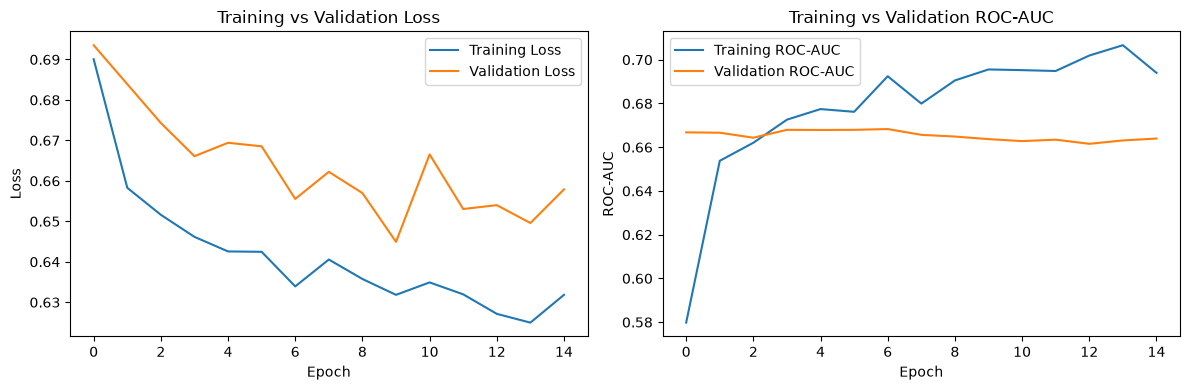

In [28]:
import matplotlib.pyplot as plt

best_epoch = min(
    range(len(history.history["val_loss"])),
    key=lambda i: history.history["val_loss"][i]
) + 1

print("Epochs completed:", len(history.history["loss"]))
print("Best epoch:", best_epoch)
print("Best validation loss:", min(history.history["val_loss"]))
print("Best validation ROC-AUC:", max(history.history["val_roc_auc"]))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["roc_auc"], label="Training ROC-AUC")
plt.plot(history.history["val_roc_auc"], label="Validation ROC-AUC")
plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("Training vs Validation ROC-AUC")
plt.legend()

plt.tight_layout()
plt.show()

In [29]:
import numpy as np

best_epoch = np.argmin(history.history["val_loss"])

print("Best epoch:", best_epoch + 1)
print("Best validation loss:",
      history.history["val_loss"][best_epoch])
print("ROC-AUC at best-loss epoch:",
      history.history["val_roc_auc"][best_epoch])
print("Best validation ROC-AUC:",
      max(history.history["val_roc_auc"]))

Best epoch: 10
Best validation loss: 0.644929051399231
ROC-AUC at best-loss epoch: 0.6636962890625
Best validation ROC-AUC: 0.668305516242981


In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Predict default probabilities
y_prob = model.predict(X_test_scaled).ravel()

# Convert probabilities into class predictions
# Threshold = 0.50
y_pred = (y_prob >= 0.50).astype(int)

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Fully Paid (0)", "Not Fully Paid (1)"],
    zero_division=0
))

print("Test ROC-AUC:", roc_auc_score(y_test, y_prob))
print(
    "Test PR-AUC (Average Precision):",
    average_precision_score(y_test, y_prob)
)


60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 298us/step
Confusion Matrix:
[[1031  578]
 [ 130  177]]

Classification Report:
                    precision    recall  f1-score   support

    Fully Paid (0)       0.89      0.64      0.74      1609
Not Fully Paid (1)       0.23      0.58      0.33       307

          accuracy                           0.63      1916
         macro avg       0.56      0.61      0.54      1916
      weighted avg       0.78      0.63      0.68      1916

Test ROC-AUC: 0.6843690721774708
Test PR-AUC (Average Precision): 0.30099804010354014


: 

### Deep Learning Model Evaluation — LendingClub

A feed-forward neural network was trained to predict whether a LendingClub loan would be fully repaid. The model used standardized features, dropout regularization, class weights to address class imbalance, and early stopping based on validation loss.

The best validation-loss result occurred at epoch 10, with a validation loss of 0.6449. On the independent test set, the model achieved 63% accuracy, a ROC-AUC of 0.6844, and a PR-AUC of 0.3010.

For the minority class, Not Fully Paid (Class 1), precision was 0.23, recall was 0.58, and the F1-score was 0.33. The model correctly identified 177 of 307 actual default cases but also generated 578 false-positive predictions.

These results indicate that the model identifies some potentially risky loans, but its default predictions need improvement. Further work could investigate decision thresholds and alternative model configurations, using validation data for model selection and retaining the test results as the initial benchmark.

# Final Report — LendingClub Loan Default Prediction

## 1. Objective
Build a deep learning model (Keras / TensorFlow) that predicts whether a loan will go unpaid (`not.fully.paid = 1`), using historical LendingClub data.

## 2. Data
- 9,578 loans, 13 input columns plus the target; no missing values and no duplicate rows.
- Target is imbalanced: 83.99% fully paid (8,045) vs 16.01% not fully paid (1,533).

## 3. Work Performed
| Task | What was done | Result |
|---|---|---|
| Feature transformation | One-hot encoded the only categorical column, `purpose` | 14 → 20 columns, all numeric |
| Exploratory analysis | Class balance, feature distributions, boxplots, group means, default rate by purpose, correlation heatmap | See findings below |
| Feature engineering | Correlation check (threshold 0.70) between input features | Only `int.rate` / `fico` (-0.715) exceeded it; `int.rate` dropped → 18 features |
| Modeling | Stratified 80/20 train/test split; StandardScaler fit on training data only; 20% of training data held out for validation | 6,129 fit / 1,533 validation / 1,916 test rows |

## 4. Key EDA Findings
- Loans that were not fully paid have higher average interest rate, DTI, installment, revolving utilization and recent inquiries, and a lower average FICO score (about 698 vs 713).
- Default rate by purpose: small business is highest (27.79%), educational 20.12%, major purchase lowest (11.21%).
- `revol.bal`, `inq.last.6mths`, `delinq.2yrs` and `pub.rec` are right-skewed; `revol.bal` has extreme outliers.
- Individual features correlate only weakly with the target, so the problem is hard.

## 5. Model
- Architecture: Dense(64, ReLU) → Dropout(0.30) → Dense(32, ReLU) → Dropout(0.20) → Dense(1, sigmoid); 3,329 parameters.
- Training: Adam (lr 0.001), binary cross-entropy, batch size 32, balanced class weights (0: 0.595, 1: 3.125), early stopping on validation loss (patience 5, best weights restored).
- Training stopped after 15 epochs; best epoch was 10 (validation loss 0.6449).

## 6. Test-Set Results (threshold 0.50)
| Metric | Fully Paid (0) | Not Fully Paid (1) |
|---|---|---|
| Precision | 0.89 | 0.23 |
| Recall | 0.64 | 0.58 |
| F1-score | 0.74 | 0.33 |

- Accuracy: 0.63 | ROC-AUC: 0.684 | PR-AUC: 0.301 (the baseline PR-AUC for random guessing is about 0.16).
- Confusion matrix: 1,031 true negatives, 578 false positives, 130 false negatives, 177 true positives.
- The model catches 177 of 307 actual defaults (58%) but flags 578 good loans as risky.

## 7. Conclusions
- The model has real but modest predictive signal: ROC-AUC 0.68 and PR-AUC about double the random baseline.
- Class weights raised default recall to 58%, at the cost of low precision (0.23) and overall accuracy of 63%. Accuracy alone is misleading on this imbalanced data.
- Validation and test ROC-AUC are similar (about 0.67 vs 0.68), so there is no sign of serious overfitting; the limit is the information in the features.
- Removing `int.rate` was justified by correlation but was not compared against the full feature set; its effect on performance is untested.

## 8. Recommendations
1. Tune the decision threshold on the validation set to balance precision and recall for the business cost of a missed default vs a rejected good loan.
2. Compare the 18-feature and 19-feature models to confirm that dropping `int.rate` does not hurt.
3. Try log-transforming or capping `revol.bal` and the other skewed features.
4. Benchmark against gradient-boosted trees (e.g. XGBoost), which often perform better on tabular data like this.
5. Add features, such as loan amount or employment history, if available.